# Namrata

In (A) you did both the thing you were asked to do, and also something much better (solve the ODE).

(B) Good that you commented all parameter declarations at the top, but better to also state the units used.

You never mention your choice of M. You do say `dx = 0.5` which seems to mean M=2, but you give no argument that this is large enough. I would say it's not large enough and that M should be at least 10.

You never explain what `gaussian_kde(t_star)` does, and it never came up in this class. However, you do superimpose the actual histogram scaled to give an estimated PDF.

The PDF of a quantity with units must also have units, which should be on the graph axis label.

(C) The hazard rate also has units (it's a rate!), which should be on the graph axis label.

(D) A population, like X, cannot be negative, so this graph is nonsense and casts doubt on everything else.

Physical science is largely about quantitatively explaining experimental data. The assigned article had many figures with experimental data, but in (G) you mention just one of them specifically (K,A, etal fig 2f).

intro 3/3; (a--g) 4+2+3.5+0+3+5+7 out of 3+4+4+4+3+5+10

<h2> <b> Physics 2280: Physical Models of Biological Systems Final Project</b></h2>
<h4>Student Name: Namrata Pradeep </h4>
<h4>Professor Name: Dr. Phillip Nelson </h4>
<h4> December 12, 2025 </h4>


<b> Background: </b> Cells are one of the most fundamental building blocks of organism, providing the functionality for life as we know it. When our cells stop working, the tissues and organs in which they provide functionality to also stop working. Hence, studying cells is an important part of biology and physiology. In particularly, the accumulation of a state or variety of cells known as senescent cells (SnCs) can explain the aging that all living animals exhibit.

Senescent cells accumulation in part due to DNA damage, damaged telomeres (shortened ends of chromosomes), and oxidative stress. They remain in the cell and cause damage via the  release of signals to nearby cells, inducing their neighbor's senescence while causing inflammation.

A study by Omer Karin and Amit Agrawal et. al aimed to identify the mechanisms by which these cells are generated and removed, and how these process vary with respect to age or time.

This sets up an excellent problem to use our understanding of both deterministic models and stochastic stimulations.
In this project, we aim to understand the change in senescent cell population over time, including how long it takes for these cells to reach a critical concentration, which can be thought of as a threshold for tissue disfunction.  

From this distribution, we can also compute the hazard function, which represents the instantaneous risk of reaching the critical threshold at a given time. This analysis helps illustrate how noise and deterministic dynamics together shape the variability in lifespan, which for so long we have considered a rather abstract and unpredictable phenomenan, different person by person.


<h2><b> Part A: Deterministic Model </b></h2>

In the background information for this project, including in the Karin and Agrawal's report, the change of the SnC population (denoted X) is defined as


$$
\frac{dX}{dt} = n t - \frac{B X}{X + k}
$$

Here we will try to understand the constants that we keep constant throughout this project.

$$n = 2.3 * 10^{-4}/day  $$
This is positive production term of senescent cell, and it being really small is favorable to keep the mouse alive and not reach the critical concentration of senescent cells.

$$Xc = 17 SnCs  $$
This is the critical concentrations of the cells before we consider one trial complete. In the experiment, this is the count of SnCs by the time the mouse has died and is usually measured experimentally.

$$\epsilon = 0.16/day  $$

$$\beta = 0.15/day  $$

$$\kappa = 0.15/day  $$

These last two terms are related to the removal of the senescent cell. When the population of senescent cells (X)  is high in our differential equation, the whole term is very small, meaning the animal is pushed closed to death (rapid accumulation of aging related dysfunction).

Otherwise, the X is very small, then the removal will be fairly robust, as is true for young children. This affect the drift, and we can plot how this might affect the removal term over time. We notice a plataeu of the max number of senescent cells that can be removed as more senescent cells come to exist (which we know is a function of age or time).


<b> Understanding the Removal Rates as a function of X </b>



<>:16: SyntaxWarning: invalid escape sequence '\k'
<>:16: SyntaxWarning: invalid escape sequence '\k'
/tmp/ipython-input-3411259079.py:16: SyntaxWarning: invalid escape sequence '\k'
  plt.title('Saturation of the feedback term for different $\kappa$')


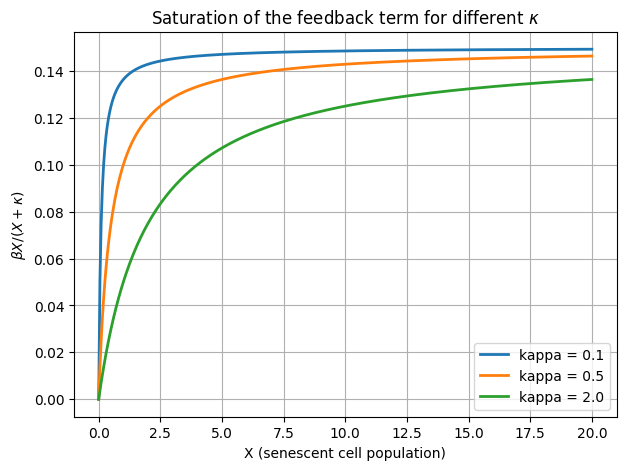

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
beta = 0.15
kappa_values = [0.1, 0.5, 2.0]  # different kappa values
X = np.linspace(0, 20, 400)

plt.figure(figsize=(7,5))
for kappa in kappa_values:
    fX = beta * X / (X + kappa)
    plt.plot(X, fX, lw=2, label=f'kappa = {kappa}')

plt.xlabel('X (senescent cell population)')
plt.ylabel(r'$\beta X / (X+\kappa)$')
plt.title('Saturation of the feedback term for different $\kappa$')
plt.legend()
plt.grid(True)
plt.show()


Now, to the actual question, we are asked to find the time at which we might reach Xc = 17, starting at X = 0. Normallly, with a differential equation, we could integrate it to find an analytical solution. However, as our is quite complicated, we can use computer math packages to integrate for a solution.

With a function X(t), we can then find out at what time the SnC population reaches 17.

<b> Differential Approximation </b>

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp

# =========================
# Parameters
# =========================
eta = 0.00023         # day^-1
beta = 0.15        # day^-1
kappa = 0.5
X0 = 0.1
Xc = 17

# define the ODE
def dX_dt(t, X):
    return eta * t - beta * X / (X + kappa)

# Solve ODE
t_span = (0, 1000)  # initial guess for max time
sol = solve_ivp(dX_dt, t_span, [X0], max_step=0.1, dense_output=True)

t_eval = np.linspace(t_span[0], t_span[1], 100000)
X_t = sol.sol(t_eval)[0]

# Find first index where X >= Xc
idx = np.argmax(X_t >= Xc)
t_star = t_eval[idx]

print("Deterministic first-passage time t* =", t_star, "days")


Deterministic first-passage time t* = 957.729577295773 days


<b> Deterministic first-passage time t* = 957.729577295773 days </b>

Before we get to the stochastic stimulation, we also know that randomness can just be manually inserted into this otherwise deterministic function via noise. We haven't really done this before, but if we were to do that, we are basically sayng that the actual removal and production rate of senescent cells is going to maybe deviate from the normal expected values as time goes on.

This makes sense in the context of aging, and also pulls our first passage time sooner.

In the continuous, deterministic approximation, X just tracks the changing minimum of u(t,x), until it hits Xc. Find the time when this occurs. Now add randomness. The minimum of U(t,x) is when dU/dX is zero. We know that force is the negative derivative of U(T,x) so we want to find out when the -force is essentially zero.

$$
f = \xi\,L\left(\eta t - \frac{\beta X_{\text{pos}}}{X_{\text{pos}} + L\kappa}\right)
$$


$$
\frac{dU}{dX} = -f = \frac{\beta X_{\text{pos}}}{X_{\text{pos}} + L\kappa} -\eta t
$$

$$\frac{\beta X_{\text{c}}}{X_{\text{c}} + \kappa} -\eta t = 0    $$

$$\frac{\beta X_{\text{c}}}{X_{\text{c}} + \kappa} = \eta t     $$

<b> at time = 633 days. </b>

Notice, how this first passage time is shorter than the one we found with theh numerical solve.

“Force = 0” gives the time when the potential minimum reaches the boundary; the ODE gives the time when the actual trajectory reaches it, and finite relaxation causes a delay.


<b> <h2> Part B: Stochastisity </b> </h3>

Simulation complete.
Mean first-passage time: 852.58
Standard deviation: 137.04


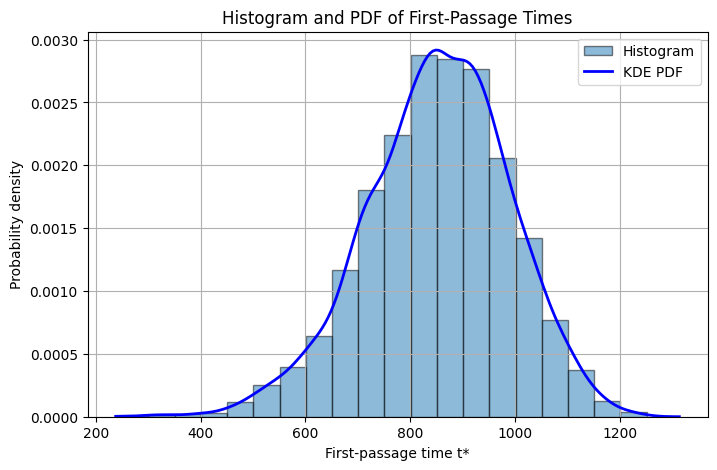

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# =========================
# Parameters
# =========================
eta = 0.00023        # deterministic drift term
beta = 0.15          # saturation coefficient
kappa = 0.5          # saturation constant
epsilon = 0.16       # noise amplitude
Xc = 17              # critical concentration
n_walkers = 5000      # number of trials

# Lattice parameters (rescaled for correct times)
dx = 0.5                       # step size
dt = dx**2 / (2*epsilon)        # time step consistent with diffusion

# Snapshot times
snapshot_times = [224, 336, 504, 672, 770, 820] #these are the days that we are asked to analyze further in later parts
snapshot_times = sorted(snapshot_times)
snapshots = {}
next_snap = 0

# =========================
# Initialize walkers
# =========================
X = np.full(n_walkers, dx)   # start at minimum
alive = np.ones(n_walkers, dtype=bool)
t_star = np.zeros(n_walkers)
t = 0.0

# Lists for <X(t)> and Std(X(t)>
X_mean = []
X_std = []
time_points = []

# =========================
# Simulation loop
# =========================
while np.any(alive):
    Xa = X[alive]

    # Compute drift per dt
    drift = eta*t - beta*Xa/(Xa + kappa)

    # Probability of stepping right (scaled correctly)
    P_plus = 0.5 * (1 + drift * dt / dx)
    P_plus = np.clip(P_plus, 0.0, 1.0)

    # Bernoulli step
    steps_right = np.random.rand(len(P_plus)) < P_plus
    Xa_new = Xa + dx * (2*steps_right - 1)

    # Reflecting boundary at minimum
    Xa_new = np.maximum(Xa_new, dx)

    # Record <X(t)> and Std(X(t)>
    if np.any(alive):
        X_mean.append(X[alive].mean())
        X_std.append(X[alive].std())
        time_points.append(t)

    # Record snapshots at specified times
    while next_snap < len(snapshot_times) and t >= snapshot_times[next_snap]:
        snapshots[snapshot_times[next_snap]] = Xa_new.copy()
        next_snap += 1

    # First-passage detection
    hit = Xa_new >= Xc
    idx_alive = np.nonzero(alive)[0]
    t_star[idx_alive[hit]] = t
    alive[idx_alive[hit]] = False

    # Update positions of remaining walkers
    X[alive] = Xa_new[~hit]

    # Advance time
    t += dt

# =========================
# Output
# =========================
print("Simulation complete.")
print(f"Mean first-passage time: {t_star.mean():.2f}")
print(f"Standard deviation: {t_star.std():.2f}")

# =========================
# Plot first-passage time PDF
# =========================
plt.figure(figsize=(8,5))
plt.hist(t_star, bins =20, density=True, alpha=0.5, edgecolor='k', label='Histogram')
kde = gaussian_kde(t_star)
t_grid = np.linspace(t_star.min()*0.95, t_star.max()*1.05, 200)
plt.plot(t_grid, kde(t_grid), color='blue', lw=2, label='KDE PDF')
plt.xlabel('First-passage time t*')
plt.ylabel('Probability density')
plt.title('Histogram and PDF of First-Passage Times')
plt.legend()
plt.grid(True)
plt.show()


<b> <h2> Part C: Estimated PDF & Hazard Function  </b> </h3>

Now we can use "Gaussian KDE" to solve for the estimated PDF and find the Hazard Function.

$$
\begin{aligned}
f(t) &= \text{PDF of first-passage times} \\
S(t) &= 1 - \int_0^t f(\tau)\,d\tau \\
h(t) &= \frac{f(t)}{S(t)}
\end{aligned}
$$



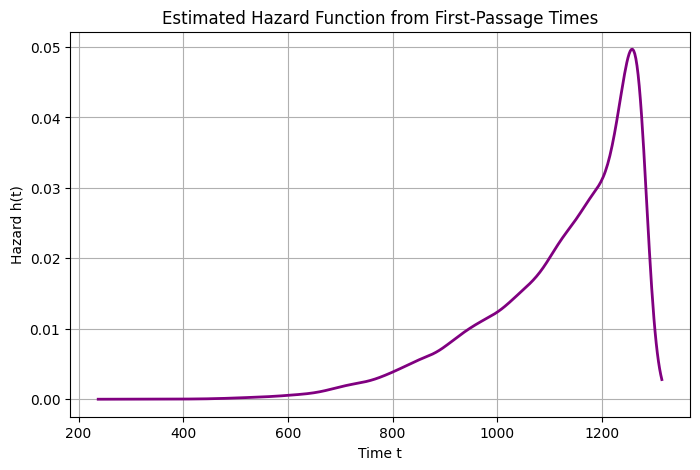

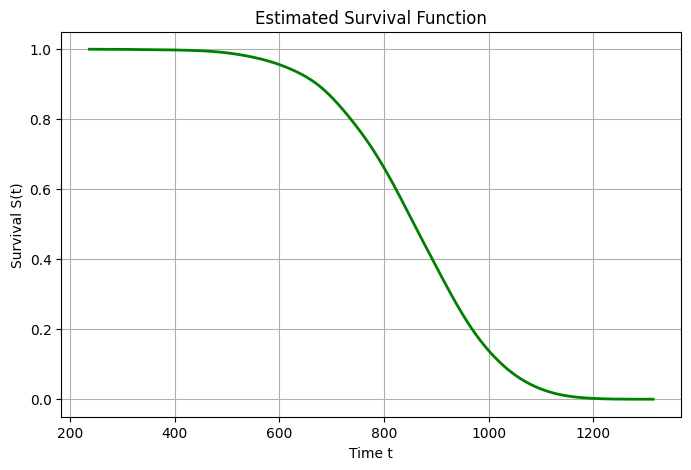

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# =========================
# Estimate PDF from first-passage times
# =========================
kde = gaussian_kde(t_star)
t_grid = np.linspace(t_star.min()*0.95, t_star.max()*1.05, 500)
pdf_est = kde(t_grid)

# Compute survival function S(t)
# S(t) = 1 - CDF
dt_grid = t_grid[1] - t_grid[0]
cdf = np.cumsum(pdf_est) * dt_grid
S = 1 - cdf

# Compute hazard function h(t) = f(t) / S(t)
# Avoid division by zero
mask = S > 1e-12
t_hazard = t_grid[mask]
hazard = pdf_est[mask] / S[mask]


plt.figure(figsize=(8,5))
plt.plot(t_hazard, hazard, color='purple', lw=2)
plt.xlabel('Time t')
plt.ylabel('Hazard h(t)')
plt.title('Estimated Hazard Function from First-Passage Times')
plt.grid(True)
plt.show()


plt.figure(figsize=(8,5))
plt.plot(t_grid, S, color='green', lw=2)
plt.xlabel('Time t')
plt.ylabel('Survival S(t)')
plt.title('Estimated Survival Function')
plt.grid(True)
plt.show()


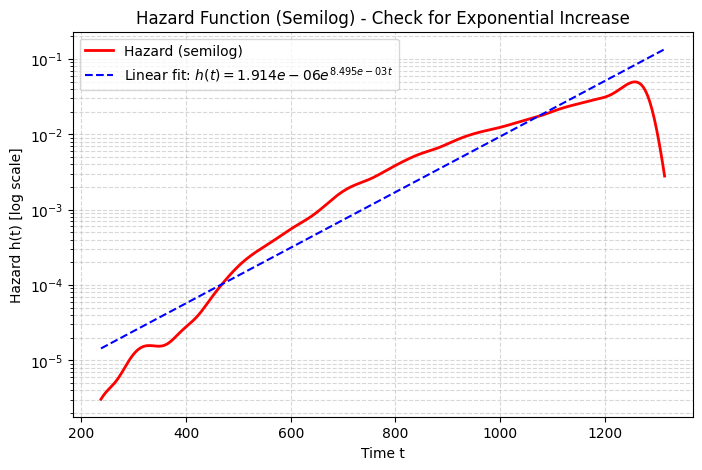

In [ ]:
from scipy.stats import linregress

# Semilog plot to check Gompertz behavior
plt.figure(figsize=(8,5))
plt.semilogy(t_hazard, hazard, color='red', lw=2, label='Hazard (semilog)')
slope, intercept, r_value, p_value, std_err = linregress(t_hazard, np.log(hazard))

# Plot the fitted line
fit_line = np.exp(intercept + slope * t_hazard)  # Exponentiate the log fit
plt.plot(t_hazard, fit_line, 'b--', label=f'Linear fit: $h(t) = {np.exp(intercept):.3e} e^{{{slope:.3e} t}}$')

plt.xlabel('Time t')
plt.ylabel('Hazard h(t) [log scale]')
plt.title('Hazard Function (Semilog) - Check for Exponential Increase')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.show()


<b> <h2> Part D & E : Population and Deviation of SnCs over time <X(t)> </b> </h3>

<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipython-input-2174922090.py:24: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(time_points, mu_values, label='Article ($\mu$)', color='blue', linewidth=2)


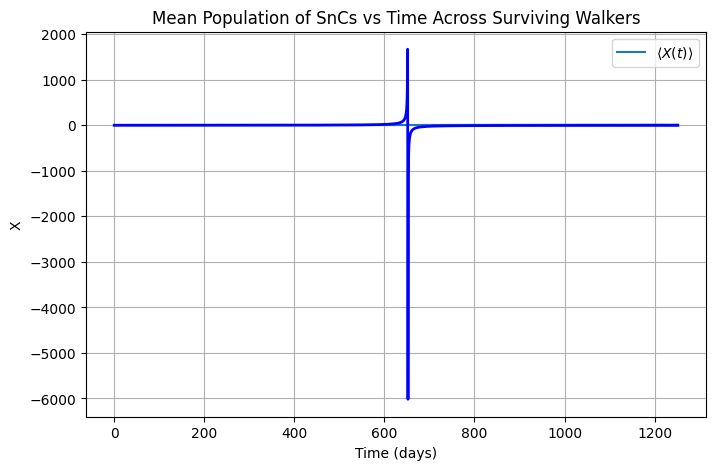

In [ ]:
# Plot <X(t)> and std(X(t)>

X_mean = np.array(X_mean)
X_std = np.array(X_std)
time_points = np.array(time_points)

plt.figure(figsize=(8,5))
plt.plot(time_points, X_mean, label=r'$\langle X(t) \rangle$')
plt.xlabel('Time (days)')
plt.ylabel('X')
plt.title('Mean Population of SnCs vs Time Across Surviving Walkers')
plt.legend()
plt.grid(True)
plt.show()

# Compute std of surviving walkers at each recorded time


The above graph shows a relatively uniform growth up until the mean lifespan of 850 days and a lot of noise and fluctuation in the average number of SnCs for those above that many days

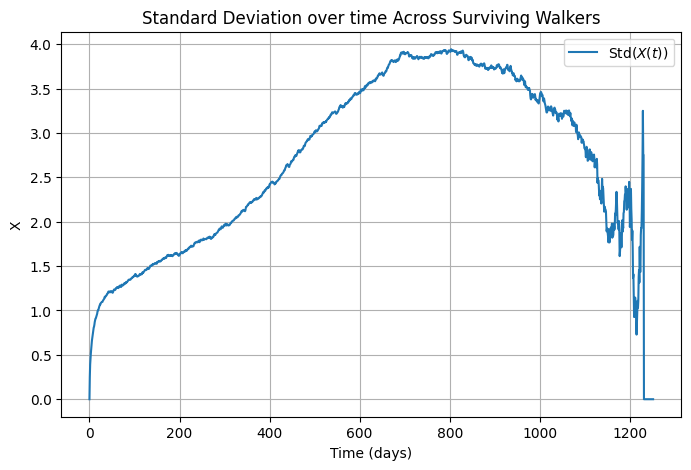

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(time_points, X_std, label=r'Std$(X(t))$')
plt.xlabel('Time (days)')
plt.ylabel('X')
plt.title('Standard Deviation over time Across Surviving Walkers')
plt.legend()
plt.grid(True)
plt.show()



<h2> <b> Part F: Estimated PDFs of X at specific points in time </b> </h2>

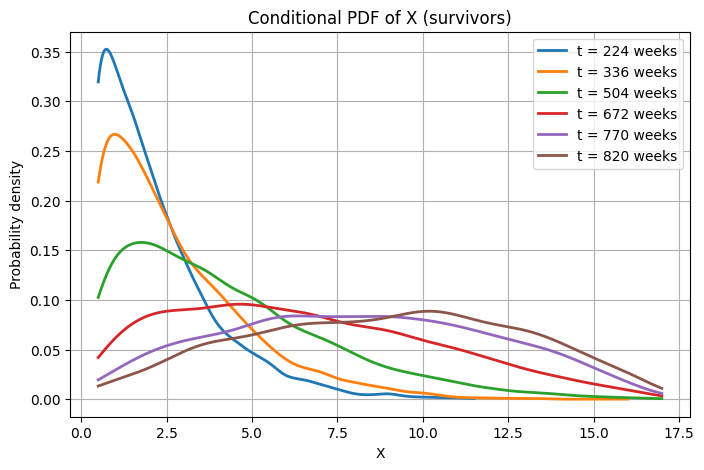

In [ ]:
plt.figure(figsize=(8,5))

for t_snap, X_snap in snapshots.items():
    kde = gaussian_kde(X_snap)
    x_grid = np.linspace(X_snap.min(), X_snap.max(), 400)
    plt.plot(x_grid, kde(x_grid), lw=2, label=f"t = {t_snap} weeks")

plt.xlabel("X")
plt.ylabel("Probability density")
plt.title("Conditional PDF of X (survivors)")
plt.legend()
plt.grid(True)
plt.show()


<b><h1> Discussion </h1> </b>


The simulation of stochastic first-passage dynamics of the senescent cell reveals several features that align closely with the  insights described in Karin & Agrawal (2017).

<b>First-Passage Times and Survival </b>

The mean first-passage time of approximately 850 days corresponds to the typical lifespan at which the senescent burden reaches the critical threshold
𝑋c= 17. The first-passage time distribution  a unimodal bell curve, consistent with the central limit effect of many stochastic models we have seen beform increments in the senescent population. This further supports the idea that, while individual trajectories fluctuate, the aggregate distribution of lifespans is well-characterized  for a particular species, hence why we can look up "lifespan of a ___" and get a distinct result.

<b> Hazard & Survival Functions </b>
The survival function exhibits a characteristic S-shaped curve, which is promising. Early in life, survival is high as Xc population is very low, hence no trials have reached first passage time yet.This is followed by a steep decline around the mean first-passage time, and a long tail as stochasticity means some trajectories to survive longer. This shows remarkable similarity to other birth death models we have analyzed, both stochastically and deterministically. The S-shaped survival curve agrees with the article, as they too have a rapid decrease in survival near the mean life span.

The hazard function, h(t)=f(t)/S(t), was also shown to follow Gompertz Law quite well, which is the idea that instantaneous hazard increases exponentially with time. Even with the randomness from the trial to trial, with a semilog fit, we did observe a continuous increase of the ln(hazard function), albeit not perfectly linear.  These reflect the increasing stochastic variability in the senescent population near the critical threshold, analogous to the “escape over a moving potential barrier” mechanism described by Karin & Agrawal.

So far, we have observed an S-Shaped Survival Curve, a Gaussian first passage time PDF, and an exponential hazard function, three different types of models to characterize the same biological system, which I made sure to stimulate once and never modify or touch again.

<b> Population of Senescent Cells over time</b>

In Karin et. Agrawal's paper, I can observed that there was a lot more fluctuation in SnCs count early on in the lifespan, while as time got closer to the mean first passage time, there was a consistant, positive growth in the senescent cell population, due to declining removal rates. However in our SnC trajectories, it seems that we have very consistent growth throughout, with greater fluctuation occuring after the mean first passage time for those cells that reemain, rather than early parts of the lifespan. STD(X) as a function of time also shown positive growth as time goes on, and I attribute that to the impact of aging on causing randomness and fluctuation on the SnC population.

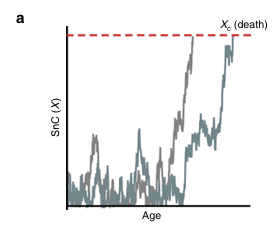






<b>Population at specific time points </b>
With a mean lifespan of 850 days, it is worthwhile to see at a specific point in time (ex. 32 week or 226 days), the population of SnCs. Our graphs did reflect the graphs shown in the paper, as we found that the most probable count of SnCs incresed as time progressed. I also included later weeks, such as 110 weeks or 770 days in my graph to observe counts as we approached the mean first passage time. Adding things like this is quite easy to do in large scale stimulations.

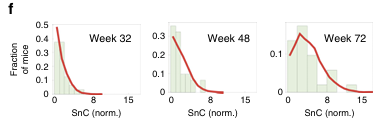

We have found that our stochastic simulation provides a mean first-passage time (lifespan) of approximately 850 days, which lies between the two initial estimates: (a) 633 days, corresponding to the time when the deterministic “force” function reaches its minimum, and (b) 933 days, obtained from solving the differential equation deterministically. This is a fascinating result, as it highlights the role of stochastic fluctuations in senescent cell accumulation. While the deterministic ODE provides a smooth trajectory and the force-minimum estimate captures a simple analytical approximation, our stochastic model incorporates the randomness inherent in biological systems, producing a distribution of lifespans that is neither as short as the force-minimum prediction nor as long as the purely deterministic solution.




<b> Acknowledgements </b>: I would like to acknowledge ChatGPT for her help in some of the coding problems I encountered.